In [37]:
import pandas as pd

In [38]:
# Extração dos dados

df = pd.read_csv(r'C:\Users\laurindo.dumba_a3dat\Documents\Projetos Machine Learning\PetroAI-Suite-main\well optimization\well_data.csv')

df.head()

,well_id,permeability_md,porosity_fraction,well_depth_ft,tubing_diameter_in,choke_size_64th,reservoir_pressure_psi,reservoir_temp_f,oil_gravity_api,gas_oil_ratio_scf_bbl,...,wellhead_pressure_psi,water_cut_fraction,oil_rate_bbl_day,gas_rate_scf_day,water_rate_bbl_day,oil_price_usd_bbl,gas_price_usd_mcf,daily_opex_usd,daily_revenue_usd,performance_index
0,1,12.142530,0.196309,10099.033155,4.500,56.787451,3317.120068,301.485497,29.126610,127.050506,...,2524.143368,0.089463,13.582132,1725.616684,1.334485,63.309370,3.477426,286.280146,579.596749,273.490500
1,2,6.434896,0.245471,9386.950524,5.500,50.899627,2704.520500,290.804258,35.655964,81.074363,...,1623.172535,0.135858,9.705185,786.841727,1.525814,65.221671,4.591461,269.658283,366.942881,202.846419
2,3,14.121360,0.080072,8089.445555,5.500,52.153051,1500.000000,271.341683,38.658243,343.423954,...,656.367946,0.234730,5.000000,1717.119770,1.533642,70.365600,4.030029,244.928098,113.819943,109.927486
3,4,33.886946,0.178148,7029.594833,4.500,45.239155,3347.177790,255.443923,46.646579,557.981435,...,2943.968788,0.214010,9.460350,5278.699868,2.575874,43.431258,2.841715,246.522699,179.352781,130.999467
4,5,5.846520,0.117468,9047.334970,2.875,22.576064,5430.092337,285.710025,40.636052,100.801256,...,4496.343854,0.223966,5.000000,504.006279,1.443012,77.071176,2.668624,254.416362,132.284522,117.543298



```markdown
# Dicionário de dados da base de poços

Cada linha representa um poço. A coluna `well_id` identifica cada registro de forma única.

## 1. Identificação

| Coluna | Descrição |
|---|---|
| `well_id` | Identificador único do poço. |

## 2. Características do reservatório e dos fluidos

| Coluna | Descrição | Unidade |
|---|---|---|
| `permeability_md` | Permeabilidade da rocha do reservatório. | mD |
| `porosity_fraction` | Porosidade da rocha, expressa como fração. | Fração |
| `reservoir_pressure_psi` | Pressão do reservatório. | psi |
| `reservoir_temp_f` | Temperatura do reservatório. | °F |
| `oil_gravity_api` | Gravidade API do petróleo, indicador de sua densidade relativa. | °API |
| `gas_oil_ratio_scf_bbl` | Razão entre o volume de gás e o volume de petróleo produzido. | scf/bbl |

## 3. Características e condições operacionais do poço

| Coluna | Descrição | Unidade |
|---|---|---|
| `well_depth_ft` | Profundidade do poço. | ft |
| `tubing_diameter_in` | Diâmetro da tubulação de produção. | pol. |
| `choke_size_64th` | Tamanho do choke, expresso em unidades de 1/64 de polegada. | 1/64 pol. |
| `bottomhole_pressure_psi` | Pressão no fundo do poço. | psi |
| `wellhead_pressure_psi` | Pressão na cabeça do poço. | psi |

## 4. Produção

| Coluna | Descrição | Unidade |
|---|---|---|
| `oil_rate_bbl_day` | Taxa diária de produção de petróleo. | bbl/dia |
| `gas_rate_scf_day` | Taxa diária de produção de gás. | scf/dia |
| `water_rate_bbl_day` | Taxa diária de produção de água. | bbl/dia |
| `water_cut_fraction` | Fração de água na produção de líquidos. | Fração |


## 5. Preços e resultados econômicos

| Coluna | Descrição | Unidade |
|---|---|---|
| `oil_price_usd_bbl` | Preço do petróleo. | USD/bbl |
| `gas_price_usd_mcf` | Preço do gás. | USD/Mcf |
| `daily_opex_usd` | Despesas operacionais diárias. | USD/dia |
| `daily_revenue_usd` | Receita diária registrada para o poço. | USD/dia |

## 6. Indicador de desempenho

| Coluna | Descrição |
|---|---|
| `performance_index` | Índice utilizado para representar o desempenho do poço. |
```

In [39]:
# Exploração da informaçõa da base de dados

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   well_id                  500 non-null    int64  
 1   permeability_md          500 non-null    float64
 2   porosity_fraction        500 non-null    float64
 3   well_depth_ft            500 non-null    float64
 4   tubing_diameter_in       500 non-null    float64
 5   choke_size_64th          500 non-null    float64
 6   reservoir_pressure_psi   500 non-null    float64
 7   reservoir_temp_f         500 non-null    float64
 8   oil_gravity_api          500 non-null    float64
 9   gas_oil_ratio_scf_bbl    500 non-null    float64
 10  bottomhole_pressure_psi  500 non-null    float64
 11  wellhead_pressure_psi    500 non-null    float64
 12  water_cut_fraction       500 non-null    float64
 13  oil_rate_bbl_day         500 non-null    float64
 14  gas_rate_scf_day         500 non-null

In [40]:
# Verificaçõe das dimensões da base de dados]

print(df.shape)

(500, 21)


In [41]:
# Verificação de dados faltantes

print(df.isnull().sum())

well_id                    0
permeability_md            0
porosity_fraction          0
well_depth_ft              0
tubing_diameter_in         0
choke_size_64th            0
reservoir_pressure_psi     0
reservoir_temp_f           0
oil_gravity_api            0
gas_oil_ratio_scf_bbl      0
bottomhole_pressure_psi    0
wellhead_pressure_psi      0
water_cut_fraction         0
oil_rate_bbl_day           0
gas_rate_scf_day           0
water_rate_bbl_day         0
oil_price_usd_bbl          0
gas_price_usd_mcf          0
daily_opex_usd             0
daily_revenue_usd          0
performance_index          0
dtype: int64


In [42]:
# Verificação da percentagem de valores faltantes em cada coluna

print(df.isnull().mean() * 100)

well_id                    0.0
permeability_md            0.0
porosity_fraction          0.0
well_depth_ft              0.0
tubing_diameter_in         0.0
choke_size_64th            0.0
reservoir_pressure_psi     0.0
reservoir_temp_f           0.0
oil_gravity_api            0.0
gas_oil_ratio_scf_bbl      0.0
bottomhole_pressure_psi    0.0
wellhead_pressure_psi      0.0
water_cut_fraction         0.0
oil_rate_bbl_day           0.0
gas_rate_scf_day           0.0
water_rate_bbl_day         0.0
oil_price_usd_bbl          0.0
gas_price_usd_mcf          0.0
daily_opex_usd             0.0
daily_revenue_usd          0.0
performance_index          0.0
dtype: float64


In [43]:
# Verificação de valores duplicados

print(f"Linhas duplicas: {df.duplicated().sum}")

Linhas duplicas: <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
495    False
496    False
497    False
498    False
499    False
Length: 500, dtype: bool>


In [44]:
# Verificação de dados categóricos existem

print(df.select_dtypes(include=['object']).columns)

Index([], dtype='str')


In [47]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


<Axes: >

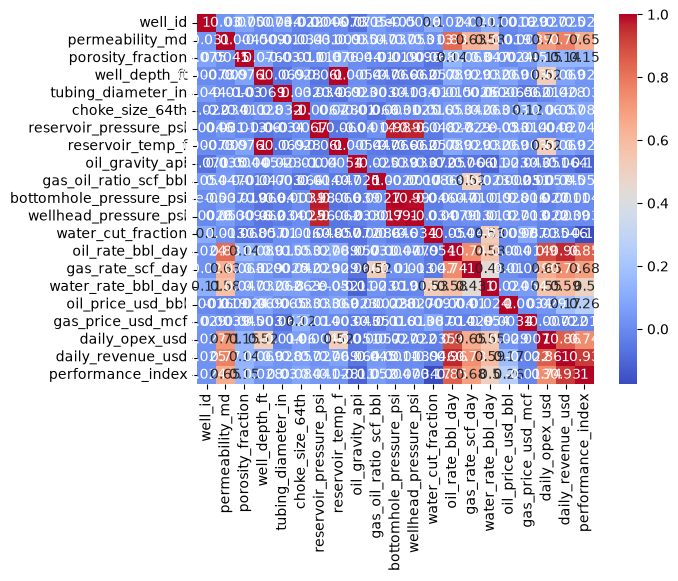

In [48]:
# Verificação da correlação entre das colunas
import seaborn as sns

import numpy as np

sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap="coolwarm")